In [1]:
print("Welcome to NewsSpace!")
print("Jupyter Notebook is working perfectly.")

Welcome to NewsSpace!
Jupyter Notebook is working perfectly.


In [3]:
import sys
print(sys.executable)


C:\Program Files\Python313\python.exe


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
import ucimlrepo

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("All imports successful!")

NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
SciPy: 1.18.1
All imports successful!


In [7]:
from pathlib import Path

csv_path = Path("data/online-news-popularity-seed-2025-800.csv")

print("Dataset found:", csv_path.exists())
print("Current working folder:", Path.cwd())


Dataset found: True
Current working folder: C:\Users\Shrithil S Shetty\OneDrive\Desktop\Juypiter foolder\Newspace


In [8]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv(csv_path)

# Clean column names
df.columns = [c.strip() for c in df.columns]

# Select the numerical features
feature_cols = [
    c for c in df.columns
    if c not in {"url", "timedelta", "shares"}
]

# Create the feature matrix and target vector
X = df[feature_cols].to_numpy(dtype=float)
y = df["shares"].to_numpy(dtype=float)

print("Dataset rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Numerical features:", X.shape[1])
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

display(df.head())

Dataset rows: 800
Total columns: 61
Numerical features: 58
Feature matrix shape: (800, 58)
Target vector shape: (800,)


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/ftc-google-leaks/,731.0,9.0,391.0,0.510256,1.0,0.650000,9.0,2.0,1.0,...,0.050000,0.35,-0.108333,-0.166667,-0.050,0.000000,0.000000,0.500000,0.000000,598
1,http://mashable.com/2013/01/07/intel-awesome-l...,731.0,12.0,1225.0,0.385452,1.0,0.508519,22.0,22.0,28.0,...,0.050000,1.00,-0.202292,-0.500000,-0.050,0.500000,0.500000,0.000000,0.500000,1800
2,http://mashable.com/2013/01/07/livio-connect-e...,731.0,11.0,315.0,0.551282,1.0,0.702247,4.0,4.0,1.0,...,0.136364,0.50,-0.320139,-0.500000,-0.125,0.550000,0.350000,0.050000,0.350000,343
3,http://mashable.com/2013/01/07/power-matters-a...,731.0,10.0,555.0,0.535390,1.0,0.708824,7.0,6.0,1.0,...,0.050000,0.70,-0.225794,-0.400000,-0.125,0.500000,-0.100000,0.000000,0.100000,1600
4,http://mashable.com/2013/01/07/samsung-smart-hub/,731.0,12.0,463.0,0.504348,1.0,0.631579,1.0,1.0,4.0,...,0.033333,0.50,-0.189410,-0.400000,-0.125,0.066667,0.033333,0.433333,0.033333,598


In [26]:
from sklearn.preprocessing import StandardScaler

# Standardize the 58 numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original matrix shape:", X.shape)
print("Standardized matrix shape:", X_scaled.shape)

print("\nFirst 5 standardized values of feature 1:")
print(X_scaled[:5, 0])

print("\nMean of first feature:", X_scaled[:, 0].mean())
print("Standard deviation of first feature:", X_scaled[:, 0].std())

Original matrix shape: (800, 58)
Standardized matrix shape: (800, 58)

First 5 standardized values of feature 1:
[-0.6112885   0.84995891  0.36287644 -0.12420603  0.84995891]

Mean of first feature: -3.552713678800501e-16
Standard deviation of first feature: 1.0


In [10]:
# Calculate the numerical rank of the standardized matrix
rank = np.linalg.matrix_rank(X_scaled)

print("Matrix shape:", X_scaled.shape)
print("Numerical rank:", rank)
print("Number of features:", X_scaled.shape[1])
print("Nullity:", X_scaled.shape[1] - rank)

Matrix shape: (800, 58)
Numerical rank: 56
Number of features: 58
Nullity: 2


In [11]:
# Take a small sample of 5 articles and 4 features
A = X_scaled[:5, :4].copy()

print("Original matrix A:")
print(np.round(A, 3))

# Gaussian elimination to obtain row-echelon form
m, n = A.shape
pivot_row = 0

for col in range(n):
    # Find the row with the largest pivot candidate
    best_row = pivot_row + np.argmax(np.abs(A[pivot_row:, col]))

    if abs(A[best_row, col]) < 1e-10:
        continue

    # Swap rows
    A[[pivot_row, best_row]] = A[[best_row, pivot_row]]

    # Eliminate entries below the pivot
    for row in range(pivot_row + 1, m):
        factor = A[row, col] / A[pivot_row, col]
        A[row] -= factor * A[pivot_row]

    pivot_row += 1

    if pivot_row == m:
        break

print("\nRow-echelon form:")
print(np.round(A, 3))
print("\nNumber of pivots:", pivot_row)

Original matrix A:
[[-0.611 -0.324 -0.217  0.143]
 [ 0.85   1.651 -1.207  0.143]
 [ 0.363 -0.504  0.108  0.143]
 [-0.124  0.064 -0.018  0.143]
 [ 0.85  -0.153 -0.264  0.143]]

Row-echelon form:
[[ 0.85   1.651 -1.207  0.143]
 [ 0.    -1.804  0.943 -0.   ]
 [ 0.     0.    -0.634  0.246]
 [ 0.     0.     0.     0.15 ]
 [ 0.     0.     0.     0.   ]]

Number of pivots: 4


In [12]:
from scipy.linalg import qr

# Pivoted QR decomposition of the standardized feature matrix
Q, R, pivots = qr(X_scaled, pivoting=True, mode="economic")

# Use the same numerical-rank tolerance as NumPy
rank = np.linalg.matrix_rank(X_scaled)

independent_indices = pivots[:rank]
independent_features = [feature_cols[i] for i in independent_indices]

print("Numerical rank:", rank)
print("Number of selected independent features:", len(independent_features))
print("\nSelected feature columns:")
for feature in independent_features:
    print(feature)

Numerical rank: 56
Number of selected independent features: 56

Selected feature columns:
kw_min_min
LDA_04
average_token_length
weekday_is_sunday
kw_max_min
self_reference_max_shares
abs_title_sentiment_polarity
weekday_is_saturday
num_imgs
data_channel_is_socmed
weekday_is_friday
num_videos
kw_min_max
min_positive_polarity
global_sentiment_polarity
self_reference_min_shares
n_tokens_title
weekday_is_monday
max_negative_polarity
data_channel_is_lifestyle
LDA_01
weekday_is_tuesday
num_keywords
data_channel_is_bus
title_sentiment_polarity
num_self_hrefs
min_negative_polarity
abs_title_subjectivity
kw_min_avg
weekday_is_thursday
data_channel_is_entertainment
n_tokens_content
num_hrefs
global_rate_negative_words
kw_max_avg
data_channel_is_world
global_subjectivity
max_positive_polarity
title_subjectivity
global_rate_positive_words
kw_avg_max
n_non_stop_unique_tokens
LDA_03
LDA_00
kw_max_max
avg_positive_polarity
data_channel_is_tech
avg_negative_polarity
rate_negative_words
kw_avg_avg
kw_

In [13]:
# Construct the candidate basis matrix
B = X_scaled[:, independent_indices]

# Verify its dimensions and rank
rank_B = np.linalg.matrix_rank(B)
rank_X = np.linalg.matrix_rank(X_scaled)

print("Original matrix shape:", X_scaled.shape)
print("Basis matrix shape:", B.shape)
print("Rank of original matrix:", rank_X)
print("Rank of basis matrix:", rank_B)

if rank_B == rank_X:
    print("\nThe selected columns span the original column space numerically.")
else:
    print("\nThe selected columns need further investigation.")

Original matrix shape: (800, 58)
Basis matrix shape: (800, 56)
Rank of original matrix: 56
Rank of basis matrix: 56

The selected columns span the original column space numerically.


In [14]:
# Select three feature columns from our basis
V = B[:100, :3]

# Calculate pairwise dot products
print("Pairwise dot products:")
print(np.round(V.T @ V, 3))

Pairwise dot products:
[[344.647  -0.484 -20.089]
 [ -0.484 102.924 -10.398]
 [-20.089 -10.398  99.564]]


In [15]:
# Use all 56 selected basis vectors
V = B.copy()

# Classical Gram-Schmidt orthogonalization
Q_list = []

for j in range(V.shape[1]):
    v = V[:, j].astype(float).copy()

    for q in Q_list:
        v -= np.dot(q, v) * q

    norm = np.linalg.norm(v)

    if norm > 1e-10:
        Q_list.append(v / norm)

Q = np.column_stack(Q_list)

print("Original basis shape:", B.shape)
print("Orthonormal basis shape:", Q.shape)

# Verify orthonormality
gram_matrix = Q.T @ Q

print("Maximum orthogonality error:",
      np.max(np.abs(gram_matrix - np.eye(Q.shape[1]))))

Original basis shape: (800, 56)
Orthonormal basis shape: (800, 55)
Maximum orthogonality error: 6.734982471029438e-09


In [16]:
# Stable orthogonalization using QR decomposition
Q_qr, R_qr = np.linalg.qr(B, mode="reduced")

print("Basis shape:", B.shape)
print("Q shape:", Q_qr.shape)
print("R shape:", R_qr.shape)

print(
    "Maximum orthogonality error:",
    np.max(np.abs(Q_qr.T @ Q_qr - np.eye(Q_qr.shape[1])))
)

print(
    "Maximum reconstruction error:",
    np.max(np.abs(B - Q_qr @ R_qr))
)

Basis shape: (800, 56)
Q shape: (800, 56)
R shape: (56, 56)
Maximum orthogonality error: 1.099120794378905e-14
Maximum reconstruction error: 3.5837999234900053e-13


In [17]:
# Project the basis matrix onto its orthonormal column space
B_projected = Q_qr @ (Q_qr.T @ B)

# Measure the reconstruction error
projection_error = np.linalg.norm(B - B_projected, ord="fro")

print("Original basis shape:", B.shape)
print("Projected matrix shape:", B_projected.shape)
print("Projection reconstruction error:", projection_error)

Original basis shape: (800, 56)
Projected matrix shape: (800, 56)
Projection reconstruction error: 6.35813027114413e-13


In [18]:
from sklearn.decomposition import PCA

# Find two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original feature matrix:", X_scaled.shape)
print("PCA representation:", X_pca.shape)

print("\nVariance explained by each component:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained:")
print(pca.explained_variance_ratio_.sum())

Original feature matrix: (800, 58)
PCA representation: (800, 2)

Variance explained by each component:
[0.09422215 0.07634095]

Total variance explained:
0.1705630948840996


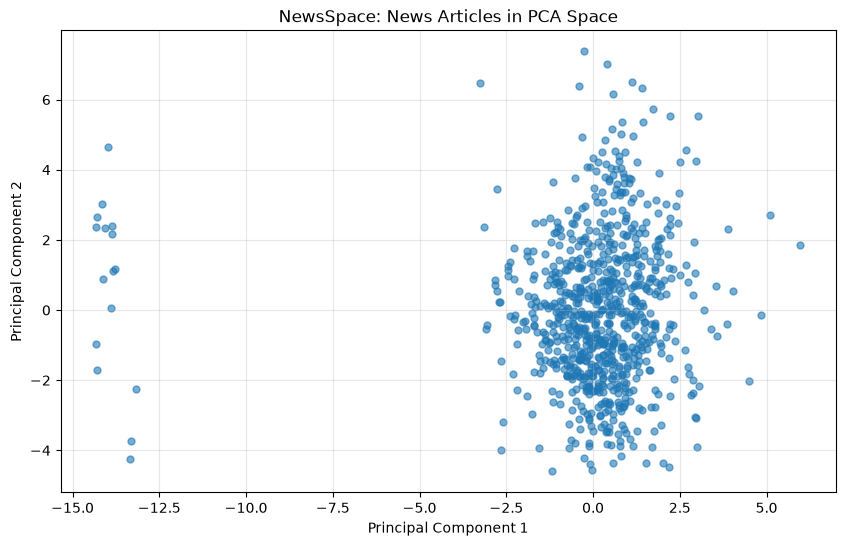

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.6,
    s=25
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("NewsSpace: News Articles in PCA Space")
plt.grid(alpha=0.3)

plt.show()


Components needed for 80% variance: 22
Components needed for 90% variance: 29
Components needed for 95% variance: 35


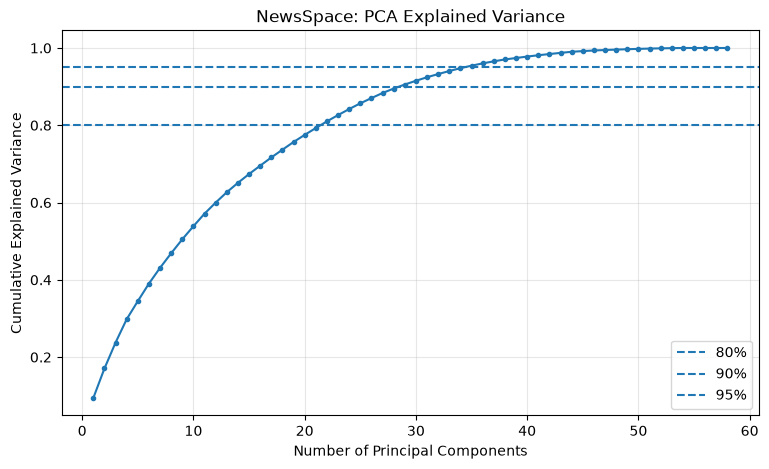

In [20]:
# Fit PCA using all available components
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

for threshold in [0.80, 0.90, 0.95]:
    n_components = np.argmax(
        cumulative_variance >= threshold
    ) + 1

    print(
        f"Components needed for {threshold:.0%} variance:",
        n_components
    )

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="."
)

plt.axhline(0.80, linestyle="--", label="80%")
plt.axhline(0.90, linestyle="--", label="90%")
plt.axhline(0.95, linestyle="--", label="95%")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("NewsSpace: PCA Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Standardize using only the training data
scaler_ls = StandardScaler()

X_train_scaled = scaler_ls.fit_transform(X_train)
X_test_scaled = scaler_ls.transform(X_test)

print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (640, 58)
Testing features: (160, 58)
Training targets: (640,)
Testing targets: (160,)


In [22]:
from sklearn.linear_model import LinearRegression

# Fit the least-squares linear regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predict shares for unseen test articles
y_pred = model.predict(X_test_scaled)

print("First 10 actual share counts:")
print(y_test[:10])

print("\nFirst 10 predicted share counts:")
print(np.round(y_pred[:10], 2))

First 10 actual share counts:
[  702.   960.  3700.  5200. 10200.  2500.   916.  1900.   753.  1600.]

First 10 predicted share counts:
[ 425.71  286.42 1224.67 1092.06  422.55 2911.1  3244.23 3126.04 3176.32
 6039.86]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

MAE: 2900.4349361478003
RMSE: 5216.363167170218
R²: -0.31230597899233903


In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train using log-transformed share counts
model_log = LinearRegression()

y_train_log = np.log1p(y_train)
model_log.fit(X_train_scaled, y_train_log)

# Predict and convert back to share counts
y_pred_log = np.expm1(model_log.predict(X_test_scaled))

# Evaluate on the original share-count scale
print("Log-target model evaluation")
print("----------------------------")
print("MAE:", mean_absolute_error(y_test, y_pred_log))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_log)))
print("R²:", r2_score(y_test, y_pred_log))

Log-target model evaluation
----------------------------
MAE: 2301.9659525269635
RMSE: 6094.298103813179
R²: -0.7912114476462799
